In [1]:
import pandas as pd
import numpy as np
import regex as re
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'D:\Download\doc\SK_WIDIASIH\dataset_kompas\databersih\data_hubunganpelakukorban.csv')

In [3]:
df.head()

,judul_berita,isi_berita,text_clean,label_kriminal,label_krim_gabungan,jenis_kriminal,prediksi_jenis_dt,motif_kejahatan,prediksi_motif_dt
0,Bocah yang Jasadnya Terbungkus Sarung Tewas Di...,"JAKARTA, KOMPAS.com - Pasangan pengemis bernam...",pasangan pengemis bernama sinta dewi 22 aidil ...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik"
1,Orangtua Bocah Tewas dalam Sarung Sering Aniay...,"JAKARTA, KOMPAS.com - Sinta Dewi (22) dan Aidi...",sinta dewi 22 aidil zacky rahman 19 pengemis d...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik"
2,Orangtua Bocah Tewas dalam Sarung Aniaya Anakn...,"JAKARTA, KOMPAS.com - Dua pengemis bernama Sin...",pengemis bernama sinta dewi 22 aidil zacky rah...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik"
3,Orangtua Bocah Tewas Terbungkus Sarung di Beka...,"JAKARTA, KOMPAS.com - Balita berinisial RMR (3...",balita berinisial rmr 3 ditemukan tewas terbun...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik"
4,"Motif Orangtua Bunuh Anak di Bekasi, Emosi kar...","JAKARTA, KOMPAS.com - Polisi mengungkapkan, or...",polisi orangtua bernama sinta dewi 22 aidil za...,True,1,Pembunuhan,Pembunuhan,"Dendam, Emosi & Konflik","Dendam, Emosi & Konflik"


In [4]:
print("Jumlah baris data:")
jumlah_baris = len(df)
print(f"   Total baris data: {jumlah_baris}")

Jumlah baris data:
   Total baris data: 63207


In [5]:
jumlah_duplikasi = df.duplicated().sum()
print("Cek data duplikasi:")
print(f"   Jumlah baris duplikat: {jumlah_duplikasi}")

Cek data duplikasi:
   Jumlah baris duplikat: 0


In [6]:
print("Cek data kosong (Missing Values):")
data_kosong = df.isnull().sum()
print(data_kosong)

Cek data kosong (Missing Values):
judul_berita           0
isi_berita             0
text_clean             0
label_kriminal         0
label_krim_gabungan    0
jenis_kriminal         0
prediksi_jenis_dt      0
motif_kejahatan        0
prediksi_motif_dt      0
dtype: int64


In [3]:
def compile_keywords_karakteristik(word_list):
    sorted_list = sorted(list(set(word_list)), key=len, reverse=True)
    return re.compile(rf"\b({'|'.join(map(re.escape, sorted_list))})\b", re.IGNORECASE)
pat_premeditasi = compile_keywords_karakteristik([
    'rencana', 'menyiapkan', 'memanfaatkan situasi','siapkan alat', 'siapkan sajam', 'siapkan senjata', 
    'siapkan tali', 'siapkan karung', 'rakit bom', 'rakit senjata', 'bawa sajam dari rumah', 'perampokan bersenjata api',
    'menyiapkan bensin', 'menyiapkan racun', 'siapkan eksekusi','menunggu tidur',
    'sasaran utama', 'intai', 'mengintai', 'survei lokasi', 'pantau situasi', 'mempelajari rute', 
    'membuntuti', 'buntuti korban', 'menunggu korban', 'menyiapkan senjata',
    'tunggu korban', 'pantau rumah', 'skenario', 'skema', 'strategi', 'sindikat', 'jaringan', 
    'organisir', 'terorganisir', 'komplotan', 'instruksi', 'perintah', 'utusan', 'pembunuh bayaran', 
    'eksekutor', 'kurir tempel', 'sistem tempel', 'bandar', 'suplier', 'distributor narkoba', 
    'penyelundupan', 'selundupkan', 'transaksi gelap', 'home industri', 'pabrik sabu', 'gandakan uang', 
    'penggandaan uang', 'dukun pengganda', 'berencana', 'pembunuhan berencana', 'direncanakan', 
    'pasal 340', 'niat jahat', 'skenario palsu', 'rekayasa', 'menyamar', 'umpan', 'jebakan', 
    'menjebak', 'modus', 'telah lama direncanakan', 'permufakatan jahat', 'persekongkolan', 
    'penipuan', 'pencucian uang', 'serial killer', 'pembunuhan berantai', 'mapping', 'bagi tugas', 
    'peran masing-masing', 'hilangkan jejak', 'hapus cctv', 'buat alibi', 'rekayasa kronologi', 
    'pola kebiasaan', 'sarung tangan', 'penutup wajah', 'sebo', 'plat palsu', 'siapkan kendaraan', 
    'joki', 'blind spot', 'titik buta', 'peta lokasi', 'unsur perencanaan', 'sistematis', 'matang', 
    'pancing korban', 'umpan wanita', 'umpan kencan', 'modus operandi', 'skenario matang','memviralkan video perundungan','pembuatan video',
    'diksar', 'pengaderan', 'aksi balas dendam', 'perdagangan manusia',
    'direncanakan sebelumnya', 'sudah disiapkan', 'berkumpul terlebih dahulu', 'berpura-pura', 
    'persiapan', 'serangan terencana', 'menunggu kedatangan', 'peredaran narkoba','mendistribusikan video','perdagangan orang','mengunggah mendistribusikan video','mendistribusikan','terindikasi penguntit','penguntit','penculikan','mencoba menculik','menculik',
])
pat_impulsif = compile_keywords_karakteristik([
    'spontan', 'emosi', 'khilaf', 'cekcok', 'refleks', 'tiba-tiba', 'kalap', 'tidak menerima teguran',
    'gelap mata', 'spontanitas', 'naik pitam', 'emosi sesaat', 'mabuk', 'fly','kesal', 
    'teler', 'pengaruh alkohol', 'pengaruh miras', 'adu mulut', 'bertengkar', 'dalam kondisi mabuk','mabuk minuman keras','sasaran amuk warga','amuk warga',
    'pertengkaran', 'tersinggung', 'hina', 'stress', 'stres', 'seketika', 'cekcok warga','dipengaruhi narkoba','dipengaruhi narkotika','dipengaruhi',
    'tanpa pikir panjang', 'khilaf mata', 'emosi meluap', 'pukul tiba tiba', 'dipengaruhi minuman keras','amuk masa','diamuk masa','diamuk warga','amuk warga',
    'reaksi', 'terprovokasi', 'provokasi', 'tersulut', 'marah besar', 'nekat', 'terlibat pesta miras','lantaran salah satunya','paspasan','tersinggung','berpapasan', 'konfrontasi', 'ribut jalanan', 'papasan','otak penculikan','penculikan',
    'depresi', 'gangguan jiwa', 'halusinasi', 'bisikan gaib', 'amuk massa', 'carok',
    'main hakim sendiri', 'kejadian mendadak', 'puncak kekesalan', 'tidak direncanakan', 
    'reaksi spontan', 'panik', 'ketakutan', 'membela diri', 'adu jotos', 'duel maut', 
    'menangis terus', 'rewel', 'susah diatur', 'kencing di kasur', 'buang air sembarangan', 
    'pecahkan piring', 'bandel', 'nakal', 'tidak mau makan', 'dimarahi', 'dicubit', 
    'disundut', 'disiram air panas', 'dipukul karena kesal', 'hilang kesabaran', 
    'pengaruh', 'perkelahian spontan', 'hanya sesaat', 'lepas kendali', 'emosi memuncak', 
    'hilang kendali', 'tidak sengaja', 'kebetulan lewat', 'melihat kesempatan', 
    'reaksi bela diri', 'overdosis', 'tak sadarkan diri', 'baby blues', 'tidak terima ditegur', 'tersinggung saat ditegur', 'marah saat dilerai', 
    'sakit hati ditegur', 'cekcok mulut', 'berselisih paham', 'saling tantang',
    'ngamuk', 'mengamuk', 'naik darah', 'lepas kendali', 'hilang akal', 
    'spontan menyerang', 'kalap', 'mendadak marah', 'emosi meledak','spontan', 'seketika', 'salah paham', 'dituduh maling', 'epilepsi', 'kambuh', 'massa', 'terprovokasi', 'amuk massa',
    'emosi tidak stabil', 'tidak sadar', 'membanting', 'melempar', 'emosi jiwa', 
    'tersinggung ucapan', 'sakit hati mendadak', 'pencabulan mendadak', 'khilaf sesaat', 
    'situasi memanas', 'perkelahian jalanan', 'bentrokan fisik', 'tanpa persiapan', 
    'insting', 'refleks pertahanan', 'pasal 338', 'tanpa niat awal', 'ketidaksengajaan', 
    'tanpa perencanaan', 'di luar rencana', 'tidak ada skenario', 'tanpa motif sebelumnya', 
    'bukan target sasaran', 'terjadi begitu saja', 'di luar dugaan', 'tanpa pertimbangan', 
    'kurang pertimbangan', 'aksi seketika', 'tanpa prasangka', 'lepas kontrol', 
    'sumbu pendek', 'hilang akal sehat', 'ledakan amarah', 'emosi tak terkendali', 
    'frustrasi mendadak', 'muntap', 'hilang kendali diri', 'hilang kesadaran', 
    'tak mampu menahan diri', 'luapan emosi', 'kejadian di tempat', 'aksi situasional', 
    'peristiwa insidental', 'terdorong keadaan', 'karena tekanan situasi', 
    'momen ketegangan', 'ketegangan mendadak', 'tekanan lingkungan', 'faktor situasi', 
    'kondisi mendesak', 'kejadian seketika itu juga', 'seketika itu juga', 
    'kurang dari hitungan menit', 'saat itu juga', 'tidak disengaja', 
    'tanpa unsur kesengajaan', 'tidak ada niat jahat sebelumnya', 'karena kekhilafan'
])
def label_karakteristik(row):
    text = f" {str(row.get('text_clean', '')).lower()} "
    
    if re.search(
    r'(pembunuhan berencana|pasal 340|direncanakan sejak)'
    r'|(menyiapkan|siapkan|persiapan).*(pisau|golok|parang|sajam|senjata)'
    r'|(siapan|menyiapkan|persiapan|mengambil|ambil).*(senjata|pisau|golok|parang|sajam)'
    r'|(rantai|gembok|mengikat|disekap|menyekap|pasung)'
    r'|(mencari\s+lawan|hunting)'
    r'|(mengajak|membawa).*(tempat sepi)'
    r'|(berulang|berkali\s+kali|rutin|setiap\s+hari|dua\s+kali|tiga\s+kali|empat\s+kali|lima\s+kali|enam\s+kali|tujuh\s+kali|delapan\s+kali|sembilan\s+kali|6\s+kali|3\s+kali)',
    text
):
        return 'Premeditasi/Terencana'

    score_pre = len(pat_premeditasi.findall(text)) * 2
    score_imp = len(pat_impulsif.findall(text)) * 2

    has_persiapan = bool(re.search(r'bawa\s+sajam|siapkan|mengintai|menunggu\s+korban', text))
    has_pemicu_spontan = bool(re.search(r'cekcok|emosi|marah|tersinggung|bertengkar', text))

    if has_persiapan and has_pemicu_spontan:
        score_pre += 2
        score_imp += 1

    white_collar = ['korupsi','pencucian uang', 'penipuan', 'skema','pembunuhan berencana','pengedar narkoba','bandar','transaksi narkoba','phising','scam','teroris','berpura pura']
    if any(k in text for k in white_collar):
        score_pre += 3
    if 'kunci' in text and 'tergantung' in text:
        return 'Impulsif/Spontan'

    if score_pre >= score_imp:
        return 'Premeditasi/Terencana'
    else:
        return 'Impulsif/Spontan'
tqdm.pandas()
df['karakteristik_kejahatan'] = df.progress_apply(label_karakteristik, axis=1)

100%|██████████| 63856/63856 [05:21<00:00, 198.83it/s] 


In [8]:
dist_kriminal = pd.DataFrame({
    'Jumlah': df['karakteristik_kejahatan'].value_counts(dropna=False),
    'Persentase (%)': (df['karakteristik_kejahatan'].value_counts(dropna=False, normalize=True) * 100).round(2)
})

print("=== DISTRIBUSI KARAKTERISTIK ===")
print(dist_kriminal)

=== DISTRIBUSI KARAKTERISTIK ===
                         Jumlah  Persentase (%)
karakteristik_kejahatan                        
Premeditasi/Terencana     52703           83.38
Impulsif/Spontan          10504           16.62


## CEK

In [ ]:
pd.set_option('display.max_colwidth', None)
df_sampel = df[df['label_kriminal'] == True].sample(n=10)

for index, row in df_sampel.iterrows():
    print(f"LABEL Jenis: {row['karakteristik_kejahatan']} | INDEX: {index}")
    print(f"BERITA ISI : {row['text_clean']}")
    print("-" * 80)
    print("\n")

In [ ]:
target_indices = [32857,49551,11402    ,8344,12253,22271,33052,53987,21135,40160,22587,28015,33949,29369,53844,3283,20307,64357,47879]

for idx in target_indices:
    if idx in df.index:
        # Langsung print tanpa peduli True atau False
        print(f"INDEX                 : {idx}")
        print(f"LABEL PERENCANAAN     : {df.loc[idx, 'karakteristik_kejahatan']}")
        print(f"BERITA ISI            : \n{df.loc[idx, 'text_clean']}")
        print("\n" + "="*80 + "\n")
    else:
        print(f"Index {idx} tidak ditemukan dalam DataFrame.")

## ML

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text_clean'],
    df['karakteristik_kejahatan'],
    test_size=0.2,
    random_state=42,
    stratify=df['karakteristik_kejahatan'] 
)

In [5]:
URUTAN_KELAS = sorted(y_train.unique())

tfidf = TfidfVectorizer(ngram_range=(1, 3), max_features=25000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [6]:
model_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
model_gini.fit(X_train_tfidf, y_train)

pred_test_gini = model_gini.predict(X_test_tfidf)

                       precision    recall  f1-score   support

     Impulsif/Spontan       0.81      0.81      0.81      2108
Premeditasi/Terencana       0.96      0.96      0.96     10664

             accuracy                           0.94     12772
            macro avg       0.89      0.89      0.89     12772
         weighted avg       0.94      0.94      0.94     12772



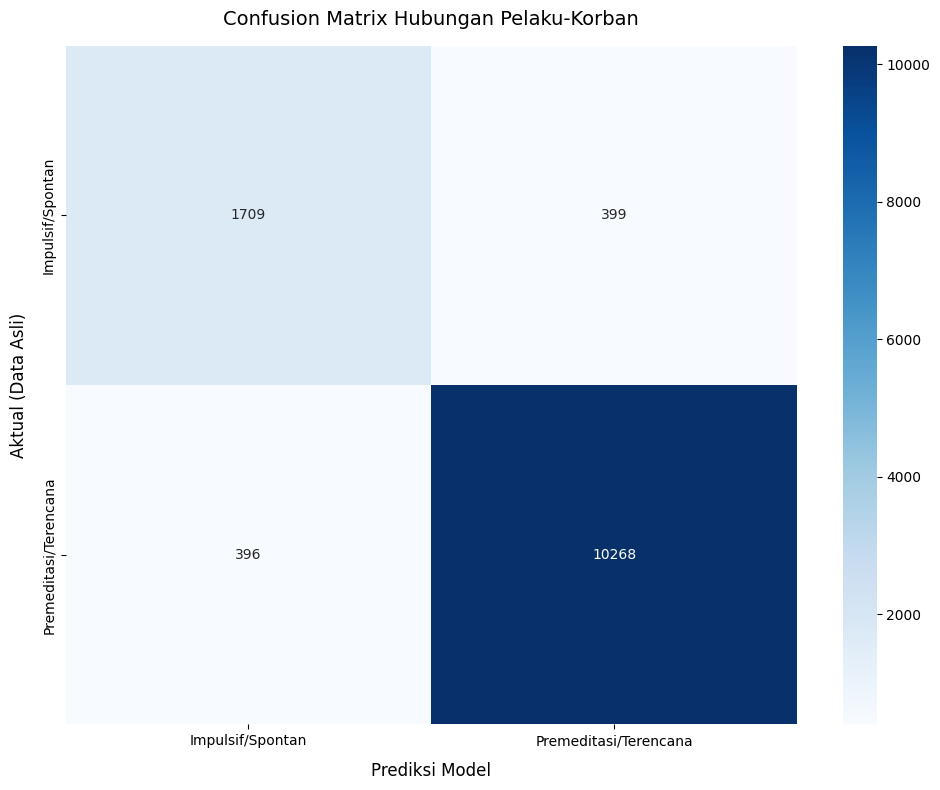


ANGKA CONFUSION MATRIX:

Data Asli [Impulsif/Spontan] didistribusikan ke prediksi:
  -> Ditebak Impulsif/Spontan: 1709
  -> Ditebak Premeditasi/Terencana: 399

Data Asli [Premeditasi/Terencana] didistribusikan ke prediksi:
  -> Ditebak Impulsif/Spontan: 396
  -> Ditebak Premeditasi/Terencana: 10268


In [7]:
print(classification_report(y_test, pred_test_gini, target_names=URUTAN_KELAS))
cm = confusion_matrix(y_test, pred_test_gini, labels=URUTAN_KELAS)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=URUTAN_KELAS,
    yticklabels=URUTAN_KELAS
)

plt.title('Confusion Matrix Hubungan Pelaku-Korban', fontsize=14, pad=15)
plt.xlabel('Prediksi Model', fontsize=12, labelpad=10)
plt.ylabel('Aktual (Data Asli)', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

print("\nANGKA CONFUSION MATRIX:")
for i, kelas_asli in enumerate(URUTAN_KELAS):
    print(f"\nData Asli [{kelas_asli}] didistribusikan ke prediksi:")
    for j, kelas_pred in enumerate(URUTAN_KELAS):
        if cm[i][j] > 0: 
            print(f"  -> Ditebak {kelas_pred}: {cm[i][j]}")

In [8]:
df_hasil_hubungan = df.copy()

X_clean_tfidf = tfidf.transform(df_hasil_hubungan['text_clean'])
prediksi_hubungan = model_gini.predict(X_clean_tfidf)
df_hasil_hubungan['prediksi_karakteristik_dt'] = prediksi_hubungan

nama_file_final = "data_karakteristikkejahatan.csv"
df_hasil_hubungan.to_csv(nama_file_final, index=False)